# 04 — Multiple Linear Regression and Polynomial Regression

This notebook applies two regression methods to the BTS data.

- **Multiple Linear Regression:** predicts passenger count from distance, month-of-year, airline, origin, and destination.
- **Polynomial Regression:** adds a squared time term to model a curved trend in total monthly passengers.

Both models train on 2025 and are evaluated on the 2026 months that BTS has published.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv(Path("data/processed/air_passenger_monthly.csv"), parse_dates=["DATE"])
df["MONTH_SIN"] = np.sin(2*np.pi*df.MONTH/12)
df["MONTH_COS"] = np.cos(2*np.pi*df.MONTH/12)
train = df[df.YEAR.eq(2025)].copy()
test = df[df.YEAR.eq(2026)].copy()
print(f"Train rows: {len(train):,} | test rows: {len(test):,}")

Train rows: 317,333 | test rows: 185,891


## A. Multiple Linear Regression at route-airline-month level
Passenger counts are right-skewed, so fit on `log1p(passengers)` and convert predictions back to passenger scale for evaluation. OneHotEncoder represents airport and carrier codes without inventing an order. Rare categories are grouped by the encoder to keep the design matrix manageable.

In [2]:
categorical = ["ORIGIN", "DEST", "UNIQUE_CARRIER"]
numeric = ["DISTANCE", "MONTH_SIN", "MONTH_COS"]
preprocess = ColumnTransformer([
    ("category", OneHotEncoder(handle_unknown="ignore", min_frequency=30), categorical),
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), numeric)
], remainder="drop")

multiple_model = Pipeline([
    ("features", preprocess),
    ("regression", LinearRegression())
])
multiple_model.fit(train[categorical + numeric], np.log1p(train.PASSENGERS))
pred = np.maximum(0, np.expm1(multiple_model.predict(test[categorical + numeric])))
print("Multiple regression — 2026 holdout")
print(f"MAE: {mean_absolute_error(test.PASSENGERS, pred):,.1f}")
print(f"RMSE: {mean_squared_error(test.PASSENGERS, pred)**0.5:,.1f}")
print(f"R²: {r2_score(test.PASSENGERS, pred):.3f}")

Multiple regression — 2026 holdout
MAE: 2,702.0
RMSE: 6,072.7
R²: 0.072


## B. Polynomial Linear Regression on monthly totals
Polynomial Regression is still linear regression: we create extra inputs (time and time²), then fit a linear model to those transformed features. Degree two can curve; higher degrees are easy to overfit, so we keep this demonstration modest.

In [3]:
totals = df.groupby("DATE", as_index=False).PASSENGERS.sum().sort_values("DATE")
totals["TIME_INDEX"] = np.arange(len(totals))
tr = totals[totals.DATE.dt.year.eq(2025)].copy()
te = totals[totals.DATE.dt.year.eq(2026)].copy()

poly_model = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("regression", LinearRegression())
])
poly_model.fit(tr[["TIME_INDEX"]], np.log1p(tr.PASSENGERS))
te["PREDICTION"] = np.maximum(0, np.expm1(poly_model.predict(te[["TIME_INDEX"]])))
print("Polynomial regression — monthly 2026 holdout")
print(f"MAE: {mean_absolute_error(te.PASSENGERS, te.PREDICTION):,.0f}")
print(f"RMSE: {mean_squared_error(te.PASSENGERS, te.PREDICTION)**0.5:,.0f}")
print(f"R²: {r2_score(te.PASSENGERS, te.PREDICTION):.3f}")
display(te[["DATE", "PASSENGERS", "PREDICTION"]])

Polynomial regression — monthly 2026 holdout
MAE: 29,206,103
RMSE: 35,629,619
R²: -16.292
         DATE   PASSENGERS    PREDICTION
12 2026-01-01   79645464.0  8.064337e+07
13 2026-02-01   76884283.0  7.477433e+07
14 2026-03-01   93999761.0  6.850461e+07
15 2026-04-01   90450847.0  6.201123e+07
16 2026-05-01   95323217.0  5.546312e+07
17 2026-06-01   97745648.0  4.901416e+07
18 2026-07-01  101606380.0  4.279787e+07


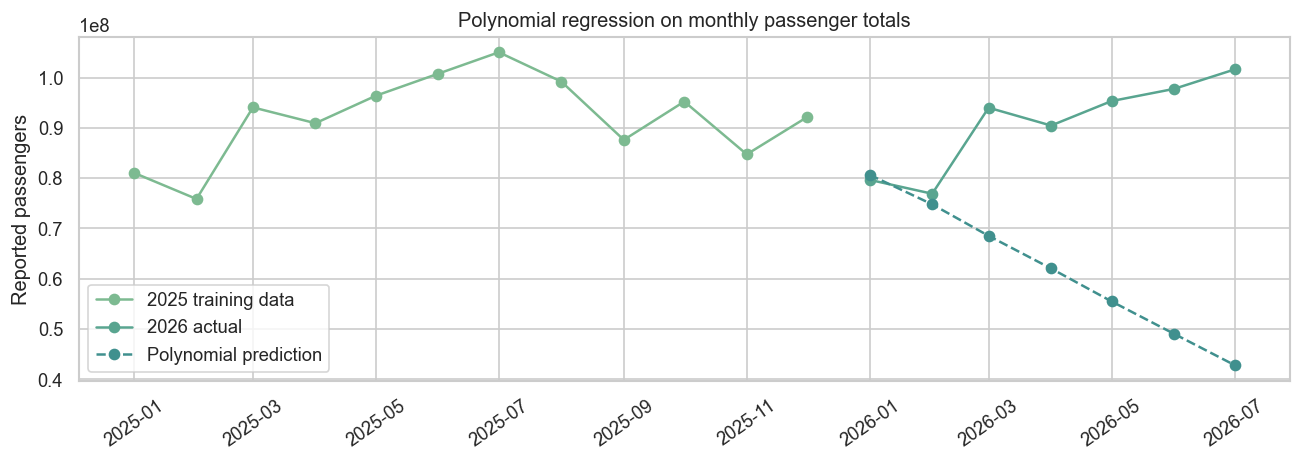

In [4]:
plt.figure(figsize=(11, 4))
plt.plot(tr.DATE, tr.PASSENGERS, marker="o", label="2025 training data")
plt.plot(te.DATE, te.PASSENGERS, marker="o", label="2026 actual")
plt.plot(te.DATE, te.PREDICTION, marker="o", linestyle="--", label="Polynomial prediction")
plt.title("Polynomial regression on monthly passenger totals")
plt.ylabel("Reported passengers")
plt.xlabel("")
plt.legend()
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

### Compare with care
The multiple model predicts each route-airline-month record; the polynomial model predicts total passengers per month. Their metrics therefore answer different questions. Compare only like-for-like targets and state the time period, unit, and train/test split alongside every score.
